In [1]:
%pip install -q "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-nature==0.7.2" "pyscf==2.10.0"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for package in ["qiskit", "qiskit-algorithms", "qiskit-nature", "pyscf", "numpy", "scipy", "scikit-learn"]:
    print(package, version(package))
print("설치 완료: 다음 실행 코드 셀로 이동합니다.")

Python: 3.13.16
qiskit 2.2.3
qiskit-algorithms 0.4.0
qiskit-nature 0.7.2
pyscf 2.10.0
numpy 2.1.3
scipy 1.16.3
scikit-learn 1.6.1
설치 완료: 다음 실행 코드 셀로 이동합니다.


Running H2 UCCSD VQE Optimization...


/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)



H2 Molecular Simulation Results
큐비트 수            : 4 / 전자 수: (1, 1)
VQE 총 에너지        : -1.13730604 Hartree
정확한 총 에너지     : -1.13730604 Hartree
핵 반발 에너지       : 0.71996899 Hartree
절대 오차            : 8.882e-16 Hartree
검증 통과: VQE가 H₂ 분자의 정확한 바닥 상태 에너지를 찾아냈습니다.


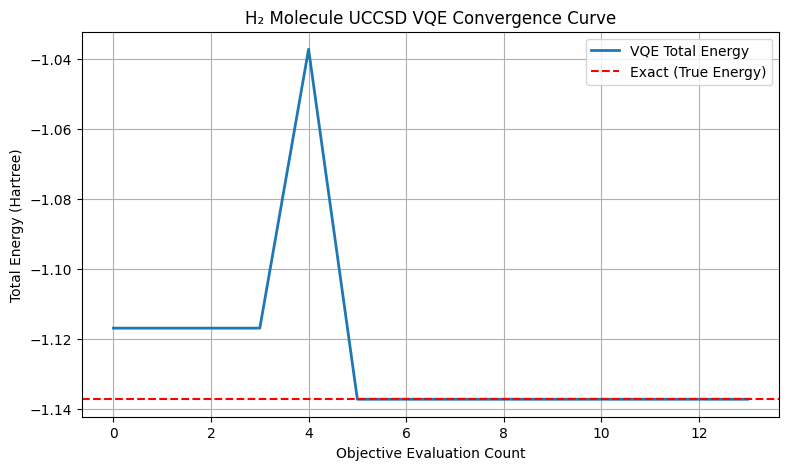

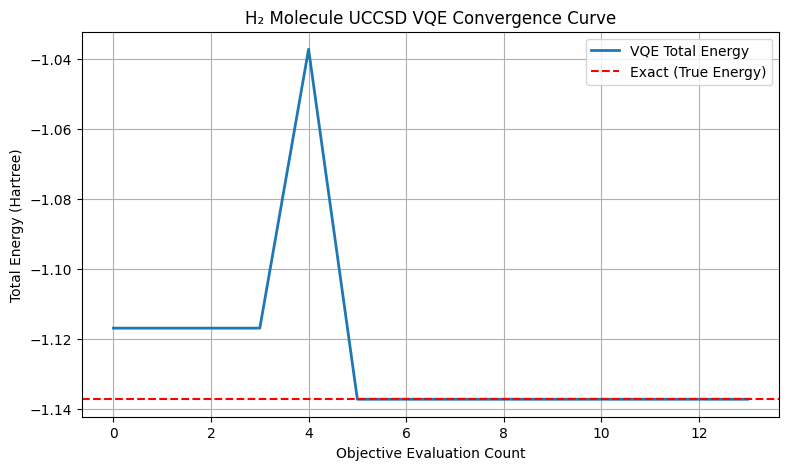

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from pyscf import lib
lib.num_threads(2)

from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD

from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP


# ==============================================================================
# STEP 2. 분자 시스템 정의 및 PySCF 드라이버 실행
# ==============================================================================
# 결합 거리 0.735 Å을 가진 수소 분자(H₂)와 sto-3g 기저함수(Basis)를 설정하고
# 화학 계산 드라이버를 실행하여 분자 정보를 얻습니다.
problem = PySCFDriver(
    atom="H 0 0 0; H 0 0 0.735",
    basis="sto3g"
).run()


# ==============================================================================
# STEP 3. 페르미온-큐비트 매핑 및 Hartree-Fock 초기 상태 정의
# ==============================================================================
# 전자들의 페르미온 연산자를 큐비트 연산자로 변환하기 위해 Jordan-Wigner 매퍼를 사용하고,
# 기준이 되는 Hartree-Fock(HF) 전자 배치 상태를 생성합니다.
mapper = JordanWignerMapper()
hf = HartreeFock(
    problem.num_spatial_orbitals,
    problem.num_particles,
    mapper
)


# ==============================================================================
# STEP 4. UCCSD 변분 회로(Ansatz) 설계
# ==============================================================================
# 전자 수와 스핀 보존 특성을 만족하는 UCCSD(Unitary Coupled Cluster Singles and Doubles)
# 변분 회로(Ansatz)를 초기 상태(hf)를 기반으로 구축합니다.
ansatz = UCCSD(
    problem.num_spatial_orbitals,
    problem.num_particles,
    mapper,
    initial_state=hf
)


# ==============================================================================
# STEP 5. 학습 기록(History)을 위한 콜백 함수 정의
# ==============================================================================
# VQE 최적화 과정에서 매 스텝마다 계산되는 에너지 값을 실시간으로 수집하여
# 학습 곡선(Convergence Curve)을 그릴 수 있도록 리스트에 저장합니다.
history = []

def callback_fn(count, params, value, meta):
    history.append(float(value))


# ==============================================================================
# STEP 6. VQE 알고리즘 설정 및 고전 최적화기(SLSQP) 초기화
# ==============================================================================
# - StatevectorEstimator: 이상적인 양자 기댓값을 고정밀로 계산
# - SLSQP: 미분 정보를 활용하여 정밀하게 파라미터를 최적화하는 고전 최적화기
# - initial_point: UCCSD 파라미터 개수만큼 0으로 초기화
vqe = VQE(
    estimator=StatevectorEstimator(seed=42),
    ansatz=ansatz,
    optimizer=SLSQP(maxiter=150, ftol=1e-10),
    initial_point=np.zeros(ansatz.num_parameters),
    callback=callback_fn
)


# ==============================================================================
# STEP 7. 해밀턴산 매핑 및 VQE 최적화 실행
# ==============================================================================
# 문제의 양자 화학 연산자를 큐비트 해밀턴산(H)으로 변환한 뒤 VQE를 실행하여
# 전자 에너지의 최솟값을 찾습니다.
H = mapper.map(problem.hamiltonian.second_q_op())

print("=" * 60)
print("Running H2 UCCSD VQE Optimization...")
print("=" * 60)
result = vqe.compute_minimum_eigenvalue(H)


# ==============================================================================
# STEP 8. 정확한 해(Exact Solution) 비교, 검증 및 시각화
# ==============================================================================
# 핵 반발 에너지(Nuclear Repulsion Energy)를 더해 최종 총 에너지를 계산하고,
# 동일 기저함수 내에서 행렬 대각화를 통한 고전적 정확한 해(Exact)와 비교합니다.
nuclear = float(problem.hamiltonian.nuclear_repulsion_energy)

m = problem.num_spatial_orbitals
na, nb = problem.num_particles
sector = [z for z in range(2**(2*m)) if (z & ((1<<m)-1)).bit_count() == na and (z >> m).bit_count() == nb]

matrix = H.to_matrix()
exact = float(np.linalg.eigvalsh(matrix[np.ix_(sector, sector)])[0]) + nuclear
energy = float(result.eigenvalue.real) + nuclear

print("\n" + "=" * 60)
print("H2 Molecular Simulation Results")
print("=" * 60)
print(f"큐비트 수            : {ansatz.num_qubits} / 전자 수: {problem.num_particles}")
print(f"VQE 총 에너지        : {energy:.8f} Hartree")
print(f"정확한 총 에너지     : {exact:.8f} Hartree")
print(f"핵 반발 에너지       : {nuclear:.8f} Hartree")
print(f"절대 오차            : {abs(energy - exact):.3e} Hartree")

# 오차 검증
assert abs(energy - exact) < 1e-5, "에너지 오차가 허용 범위를 초과했습니다!"
print("검증 통과: VQE가 H₂ 분자의 정확한 바닥 상태 에너지를 찾아냈습니다.")

# 총 에너지 감소 추이 시각화
fig = plt.figure(figsize=(9, 5))

plt.plot(np.array(history) + nuclear, label="VQE Total Energy", linewidth=2)
plt.axhline(exact, color="red", linestyle="--", label="Exact (True Energy)")

plt.xlabel("Objective Evaluation Count")
plt.ylabel("Total Energy (Hartree)")
plt.title("H₂ Molecule UCCSD VQE Convergence Curve")
plt.grid(True)
plt.legend()

display(fig)
plt.show()